In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import xarray as xr
import scipy.stats as stats
from scipy.integrate import simpson
import matplotlib.pyplot as plt
import tqdm as tqdm


In [9]:
import pickle
with open(r"/data/keeling/a/cstraus2/Phd_research/Apr_2_Oct_KDE_pdfs_multidf_withjoint_bw.5.pkl", "rb") as f:
   Apr_2_Oct_KDE_pdf_multi_station_df =  pickle.load( f)

with open(r"/data/keeling/a/cstraus2/Phd_research/Apr_2_Oct_Station_events_data_multidf_negdeltas_del.pkl", "rb") as f:
   Apr_2_Oct_Station_events_df = pickle.load(f)

with open(r"/data/keeling/a/cstraus2/Phd_research/Apr_2_Oct_min_max_df.pkl", "rb") as f:
   Apr_2_Oct_Station_min_max_df = pickle.load(f)

calculate shannon's entropy and then the mutual information

shannon's entropy, H(X) = sum(p(x_i)*log(1/p(x_i))) = -sum(p(x_i)*log(p(x_i)))

mutual information, I(x,y) = H(x) - H(x|y) or H(y) - H(y|x) or H(x) + H(y) -H(x,y)
use third because .gaussian_kde() can calculate joint pdf so this formula is easiest coding wise

use log based 2 following goodwell and hsu's papers. base 2 indicates binary systems, so yes/no for relationship interpretations

In [3]:
new_test = Apr_2_Oct_Station_min_max_df.Min
new_test
#mask = new_test.index.str.contains("Precipitation|Delta", regex=True)
#filtered_test = new_test[mask]
#filtered_test
#filtered_test[filtered_test.index.get_level_values(0).str.contains('Avg_Precipitation_rate_in')].iloc[0]

Station  Column                      
bbc      Event_Duration                  1.000000
         Avg_Precipitation_rate_in       0.000242
         Peak_Precipitation_rate_in      0.002000
         Median_Precipitation_rate_in    0.000000
         Total_Precipitation_in          0.002000
                                           ...   
siu      Peak_sm_10                      0.000000
         Prior_sm_100                    0.000000
         Peak_sm_100                     0.000000
         Delta_sm_10                     0.000000
         Delta_sm_100                    0.000000
Name: Min, Length: 220, dtype: float64

In [78]:
test = Apr_2_Oct_KDE_pdf_multi_station_df.loc['bbc', 'KDE_Object']
test
#test2 = test[test.index.get_level_values(0).str.contains('Avg_Precipitation_rate_in', regex = True)]
#test3 = test2[test2.index.get_level_values(1) == 'individual'].iloc[0]
#test3
#test2

/tmp/ipykernel_64769/2403596072.py:1: PerformanceWarning: indexing past lexsort depth may impact performance.
  test = Apr_2_Oct_KDE_pdf_multi_station_df.loc['bbc', 'KDE_Object']


Column                                              Type      
Event_Duration                                      individual    <scipy.stats._kde.gaussian_kde object at 0x153...
jointkde_Avg_Precipitation_rate_in_Delta_sm_10      joint         <scipy.stats._kde.gaussian_kde object at 0x153...
jointkde_Avg_Precipitation_rate_in_Delta_sm_100     joint         <scipy.stats._kde.gaussian_kde object at 0x153...
Avg_Precipitation_rate_in                           individual    <scipy.stats._kde.gaussian_kde object at 0x153...
jointkde_Peak_Precipitation_rate_in_Delta_sm_10     joint         <scipy.stats._kde.gaussian_kde object at 0x153...
jointkde_Peak_Precipitation_rate_in_Delta_sm_100    joint         <scipy.stats._kde.gaussian_kde object at 0x153...
Peak_Precipitation_rate_in                          individual    <scipy.stats._kde.gaussian_kde object at 0x153...
jointkde_Median_Precipitation_rate_in_Delta_sm_10   joint         <scipy.stats._kde.gaussian_kde object at 0x153...
jointkde_

Both the kde data and the event data should be in the format of layered dataframes in a dictionary where the organizing key is the station and each station's corresponding dataframe should have the same column names
the columnn names are: ['Avg_Precipitation_rate_in',  'Peak_Precipitation_rate_in', 
                       'Median_Precipitation_rate_in',  'Total_Precipitation_in',
                       'Prior_sm_10', 'Peak_sm_10',  'Prior_sm_100',  'Peak_sm_100']

 #calculate the integral of the pdf (area under curve) and then divide by this to obtain 
            #probablities as fractions [0,1]
            col_integral = np.trapz(col_pdf_values, x_vals)

            col_pvals = col_pdf_values / col_integral

            print("area", col_integral)
            print('pvals,', col_pvals[:10])

the integral is not summing to 1, so the scaling doesn't work. The KDE seems to produce a pdf that has very extensive tails

measurment error is 0/100s

In [10]:
def calc_entropy(kde_df_Series_data, min_max_df):

    station_entropies = {}
    kde_df_Series_data = kde_df_Series_data.sort_index() 

    for s, group in kde_df_Series_data.groupby(level = 'Station'):
        print(s)

        kde_Series_all = kde_df_Series_data.loc[(s, 'KDE_Object')]
        kde_Series_select_vars = kde_Series_all[
            kde_Series_all.index.get_level_values(0).str.contains("Precipitation|Delta", 
                                                                        regex = True)]
        
        print(f"Filtered KDE variables for {s}: {kde_Series_select_vars}")

         # Ensure there are valid columns
        if kde_Series_select_vars.empty:
            print(f"⚠️ No valid KDE variables found for {s}")
            continue
      
        entropy_cols = [f"{var}_entropy" for var in kde_Series_select_vars.index.get_level_values(0)]
        entropy_values = {}  # Dict to store values for one row  # DataFrame to store entropies for this station
       
        station_cols_min_vals = min_max_df.Min.loc[s]
        station_cols_max_vals = min_max_df.Max.loc[s]
        keep_vars = station_cols_min_vals.index.str.contains('Precipitation|Delta', regex = True)
        filtered_min_vals = station_cols_min_vals[keep_vars]
        filtered_max_vals = station_cols_max_vals[keep_vars]

        print(f"Filtered min values: {filtered_min_vals}")
        print(f"Filtered max values: {filtered_max_vals}")

        if filtered_min_vals.empty or filtered_max_vals.empty:
            print(f"⚠️ No valid min/max values for {s}")
            continue

        num_col = len(filtered_min_vals)

        H_cols = []
        for i in range(0,num_col):
            print(f"Processing column {i+1}/{num_col}")
            x_var_label = filtered_min_vals.index[i]
            col_min = filtered_min_vals.iloc[i]
            col_max = filtered_max_vals.iloc[i]

            print('current variable:', x_var_label)
            print('column min and max', (col_min, col_max))
            #pull in kde object for this column
            col_kde_objs = kde_Series_select_vars[
                kde_Series_select_vars.index.get_level_values(0).str.contains(x_var_label)]
            
            if col_kde_objs.empty:
                print(f"⚠️ No KDE object found for {x_var_label}")
                continue

            col_kde_ind = col_kde_objs[col_kde_objs.index.get_level_values(1) == 'individual']
            col_kde_ind_obj = col_kde_ind.iloc[0]
            
            
            #create x values to apply kde object to beased on data range
            #use datasets' min and max 
            x_vals = np.linspace(col_min-0.1 , col_max+0.1, 100) 

            #apply kde to the x values array to produce densities 
            col_pdf_values = col_kde_ind_obj(x_vals)
            
            #calculate the integral of the pdf (area under curve) and then multiply to normalize the pdf
            #(not super necessary as the intgeral is close to 1 already)
            col_integral = simpson(col_pdf_values, x = x_vals)
            col_norm = col_pdf_values / col_integral
            col_norm_integral = simpson(col_norm, x = x_vals)
            print("area (should be ~1)", col_integral)
            print("integral of normalized pdf = ", col_norm_integral)

            #calculate the probabilities for each step in the x_vals
            dx = x_vals[1]-x_vals[0]
            col_pvals = []
            for n in range(1, len(x_vals)):
                prob_n = simpson(col_norm[n - 1:n + 1], dx = dx)
                col_pvals.append(prob_n)

            #cumulative_probs = np.cumsum(col_pvals)
            
            #print('pvals,', col_pvals[:10])

            #apply log base 2 to the pdfs, multiply by p then sum
            # - sum(pi*lg2(pi))
            pdf_log2 = np.log2(col_pvals)

            H_cols = -np.sum(col_pvals * pdf_log2)

            print('entropy of this column =  ', H_cols)
            entropy_values[x_var_label + "_entropy"] = H_cols

            if col_kde_ind.index.get_level_values(0).str.contains('Delta').any():
                print(f"Skipping joint KDE calculation for {x_var_label} due to 'Delta'")
                #we calculate the joints using the precip containing columns so to avoid double
                #cal of joint we have to skip 
                continue
            else:
                print('calculating the joint entropy')
                col_kde_joints = col_kde_objs[col_kde_objs.index.get_level_values(1) == 'joint']
                

                for (joint_label, col_kde_single_joint) in col_kde_joints.items():
                    print(f"Processing joint KDE for {joint_label}")
                    joint_kde_name = joint_label[0].replace("jointkde_", "")

                    # Ensure this joint KDE starts with the current x_var_label
                    if not joint_kde_name.startswith(x_var_label + "_"):
                        print(f"⚠️ Joint label '{joint_kde_name}' does not start with expected x_var '{x_var_label}'")
                        continue
                    y_var = joint_kde_name[len(x_var_label) + 1:]
                    print(f"Parsed y_var: {y_var}")

                    try:
                        y_min = filtered_min_vals[y_var]
                        y_max = filtered_max_vals[y_var]
                    except KeyError:
                        print(f"⚠️ Could not find min/max for {y_var}")
                        continue
                    
                    y_vals_delta = np.linspace(y_min-0.1 , y_max+0.1, 100)

                    #pair data in meshgrd and flatten to 2xN array for kde
                    X_precip, Y_delta =np.meshgrid(x_vals, y_vals_delta)
                    positions = np.vstack([X_precip.ravel(), Y_delta.ravel()])
                    Z_densities = np.reshape(col_kde_single_joint(positions), X_precip.shape)

                    # Normalize the joint density (integrate over all grid points (double integral))
                    joint_integral = simpson(simpson(Z_densities, x=y_vals_delta), x=x_vals) #should sum to 1
                    joint_pdf = Z_densities / joint_integral  # Normalize to get probability distribution

                    # Compute joint probabilities using dx * dy integration
                    dx = x_vals[1] - x_vals[0]
                    dy = y_vals_delta[1] - y_vals_delta[0]
                    joint_pvals = joint_pdf * dx * dy  # Discretized probability mass function

                    # Compute log2 probabilities, avoiding log(0) by masking zeros
                    joint_pvals_flat = joint_pvals.ravel()
                    joint_pvals_flat = joint_pvals_flat[joint_pvals_flat > 0]  # Remove zero probabilities
                    log2_pvals = np.log2(joint_pvals_flat)

                    # Calculate joint entropy
                    H_joint = -np.sum(joint_pvals_flat * log2_pvals)

                    print(f'Joint entropy between {x_var_label} and {y_var}: {H_joint}')
                    entropy_values[f'joint_entropy_{x_var_label}_{y_var}'] = H_joint
        if entropy_values:
            entropy_df = pd.DataFrame([entropy_values])  # one row
            station_entropies[s] = entropy_df
        else:
            print(f"⚠️ No entropy values computed for station {s}")

    return station_entropies


In [11]:
Entropies = calc_entropy(Apr_2_Oct_KDE_pdf_multi_station_df, Apr_2_Oct_Station_min_max_df)            


bbc
Filtered KDE variables for bbc: Column                                              Type      
Avg_Precipitation_rate_in                           individual    <scipy.stats._kde.gaussian_kde object at 0x153...
Delta_sm_10                                         individual    <scipy.stats._kde.gaussian_kde object at 0x153...
Delta_sm_100                                        individual    <scipy.stats._kde.gaussian_kde object at 0x153...
Median_Precipitation_rate_in                        individual    <scipy.stats._kde.gaussian_kde object at 0x153...
Peak_Precipitation_rate_in                          individual    <scipy.stats._kde.gaussian_kde object at 0x153...
Total_Precipitation_in                              individual    <scipy.stats._kde.gaussian_kde object at 0x153...
jointkde_Avg_Precipitation_rate_in_Delta_sm_10      joint         <scipy.stats._kde.gaussian_kde object at 0x153...
jointkde_Avg_Precipitation_rate_in_Delta_sm_100     joint         <scipy.stats._kde.gauss

In [6]:
Entropies

{'bbc':    Avg_Precipitation_rate_in_entropy  \
 0                           4.838376   
 
    joint_entropy_Avg_Precipitation_rate_in_Delta_sm_10  \
 0                                          10.955403     
 
    joint_entropy_Avg_Precipitation_rate_in_Delta_sm_100  \
 0                                          10.236066      
 
    Peak_Precipitation_rate_in_entropy  \
 0                            5.034723   
 
    joint_entropy_Peak_Precipitation_rate_in_Delta_sm_10  \
 0                                           10.73268      
 
    joint_entropy_Peak_Precipitation_rate_in_Delta_sm_100  \
 0                                          10.397023       
 
    Median_Precipitation_rate_in_entropy  \
 0                              5.128208   
 
    joint_entropy_Median_Precipitation_rate_in_Delta_sm_10  \
 0                                          11.072294        
 
    joint_entropy_Median_Precipitation_rate_in_Delta_sm_100  \
 0                                          10.398944   

In [95]:
Entropies['bbc']

,Avg_Precipitation_rate_in_entropy,joint_entropy_Avg_Precipitation_rate_in_Delta_sm_10,joint_entropy_Avg_Precipitation_rate_in_Delta_sm_100,Peak_Precipitation_rate_in_entropy,joint_entropy_Peak_Precipitation_rate_in_Delta_sm_10,joint_entropy_Peak_Precipitation_rate_in_Delta_sm_100,Median_Precipitation_rate_in_entropy,joint_entropy_Median_Precipitation_rate_in_Delta_sm_10,joint_entropy_Median_Precipitation_rate_in_Delta_sm_100,Total_Precipitation_in_entropy,joint_entropy_Total_Precipitation_in_Delta_sm_10,joint_entropy_Total_Precipitation_in_Delta_sm_100,Delta_sm_10_entropy,Delta_sm_100_entropy
0,4.237926,9.182191,7.960665,5.070571,9.718857,8.351211,3.980019,9.061047,7.839411,5.293383,9.989304,8.249919,4.877487,3.670085


### Mutual information (MI): H(x) + H(y) - H(x,y)
normalized MI: Cxy = I(x,y)/H(y) and Cyx = I(x,y)/H(x)


In [5]:
def mutual_information_calc(entropies_dict):
    Stations = list(entropies_dict.keys())
    Station_MI = []

    for s in Stations:
        print('station', s)
        station_entropy_df = entropies_dict[s]
        # Step 1: Get columns for H(X) and H(Y) (without 'joint_' prefix)
        individual_columns = [col for col in station_entropy_df.columns if 'joint_' not in col]

        # Step 2: Get columns for H(X, Y) (with 'joint_' prefix)
        joint_columns = [col for col in station_entropy_df.columns if 'joint_' in col]
        mutual_information = {}
        for joint_col in joint_columns:
            found = False
            joint_label = joint_col.replace('joint_entropy_', '')
            print('Joint col', joint_col)
            print('Joint label', joint_label)

            for col_x in individual_columns:
                for col_y in individual_columns:
                    if col_x == col_y:
                        continue  # skip self-pairs

                    # Remove the '_entropy' suffix to get base names
                    col_x_base = col_x.removesuffix('_entropy')
                    col_y_base = col_y.removesuffix('_entropy')

                    expected_joint_col = f"joint_entropy_{col_x_base}_{col_y_base}"

                    if expected_joint_col == joint_col:
                        print('match found')
                        # Find the corresponding individual entropy columns
                        # Match found — calculate MI
                        H_X = station_entropy_df[col_x]
                        print('H_X', H_X)
                        H_Y = station_entropy_df[col_y]
                        print('H_Y', H_Y)
                        H_XY = station_entropy_df[joint_col]
                        print('H_XY', H_XY)

                        MI = H_X + H_Y - H_XY
                        MI_label = 'MI_'+ col_x + '_and_' + col_y

                        for idx, val in MI.items():
                            Station_MI.append({
                                "station": s,
                                "index": idx,
                                "MI_label": MI_label,
                                "mutual_information": val
                            })

                        found = True
                        break  # inner loop
                if found:
                    break  # outer loop   


    return pd.DataFrame(Station_MI)

In [12]:
MIs = mutual_information_calc(Entropies)

station bbc
Joint col joint_entropy_Avg_Precipitation_rate_in_Delta_sm_10
Joint label Avg_Precipitation_rate_in_Delta_sm_10
match found
H_X 0    5.100976
Name: Avg_Precipitation_rate_in_entropy, dtype: float64
H_Y 0    5.770654
Name: Delta_sm_10_entropy, dtype: float64
H_XY 0    10.978546
Name: joint_entropy_Avg_Precipitation_rate_in_Delta_sm_10, dtype: float64
Joint col joint_entropy_Avg_Precipitation_rate_in_Delta_sm_100
Joint label Avg_Precipitation_rate_in_Delta_sm_100
match found
H_X 0    5.100976
Name: Avg_Precipitation_rate_in_entropy, dtype: float64
H_Y 0    4.63548
Name: Delta_sm_100_entropy, dtype: float64
H_XY 0    9.858753
Name: joint_entropy_Avg_Precipitation_rate_in_Delta_sm_100, dtype: float64
Joint col joint_entropy_Peak_Precipitation_rate_in_Delta_sm_10
Joint label Peak_Precipitation_rate_in_Delta_sm_10
match found
H_X 0    5.853234
Name: Peak_Precipitation_rate_in_entropy, dtype: float64
H_Y 0    5.770654
Name: Delta_sm_10_entropy, dtype: float64
H_XY 0    11.441568
N

In [13]:
MIs.loc[MIs['station'] == 'bbc']


,station,index,MI_label,mutual_information
0,bbc,0,MI_Avg_Precipitation_rate_in_entropy_and_Delta...,-0.106916
1,bbc,0,MI_Avg_Precipitation_rate_in_entropy_and_Delta...,-0.122297
2,bbc,0,MI_Peak_Precipitation_rate_in_entropy_and_Delt...,0.182320
3,bbc,0,MI_Peak_Precipitation_rate_in_entropy_and_Delt...,0.314585
4,bbc,0,MI_Median_Precipitation_rate_in_entropy_and_De...,-0.261204
5,bbc,0,MI_Median_Precipitation_rate_in_entropy_and_De...,-0.266093
6,bbc,0,MI_Total_Precipitation_in_entropy_and_Delta_sm...,0.198791
7,bbc,0,MI_Total_Precipitation_in_entropy_and_Delta_sm...,0.720110


/tmp/ipykernel_64769/2360902302.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


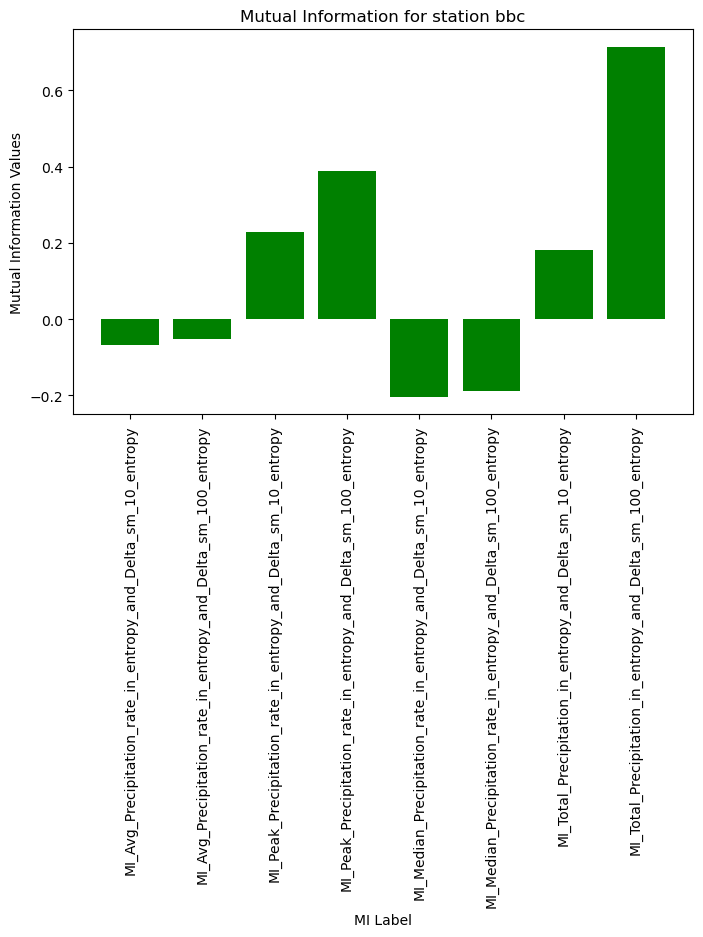

/tmp/ipykernel_64769/2360902302.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


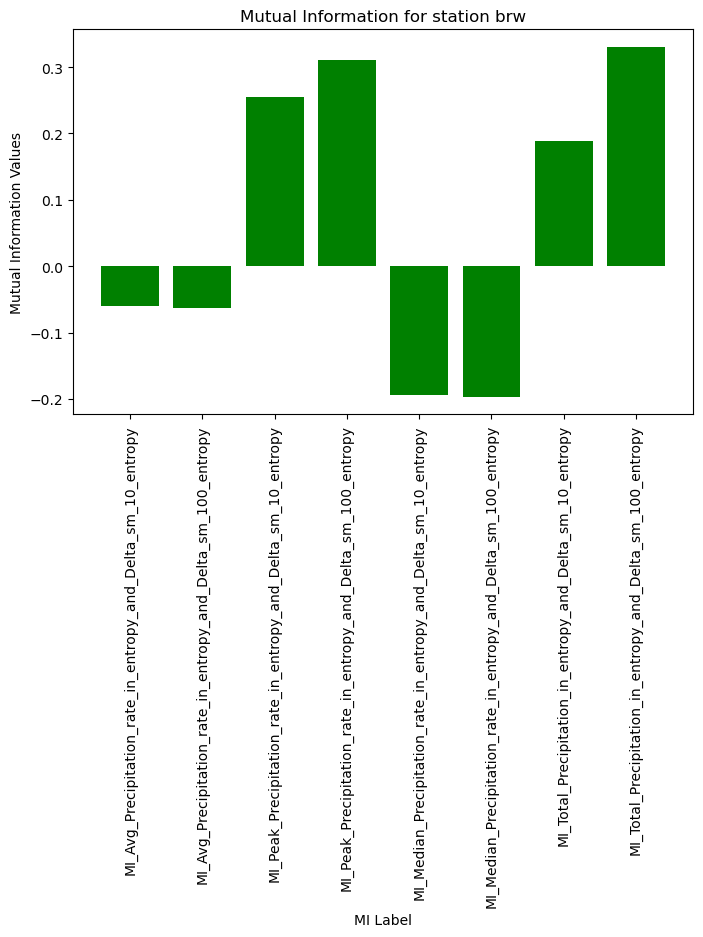

/tmp/ipykernel_64769/2360902302.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


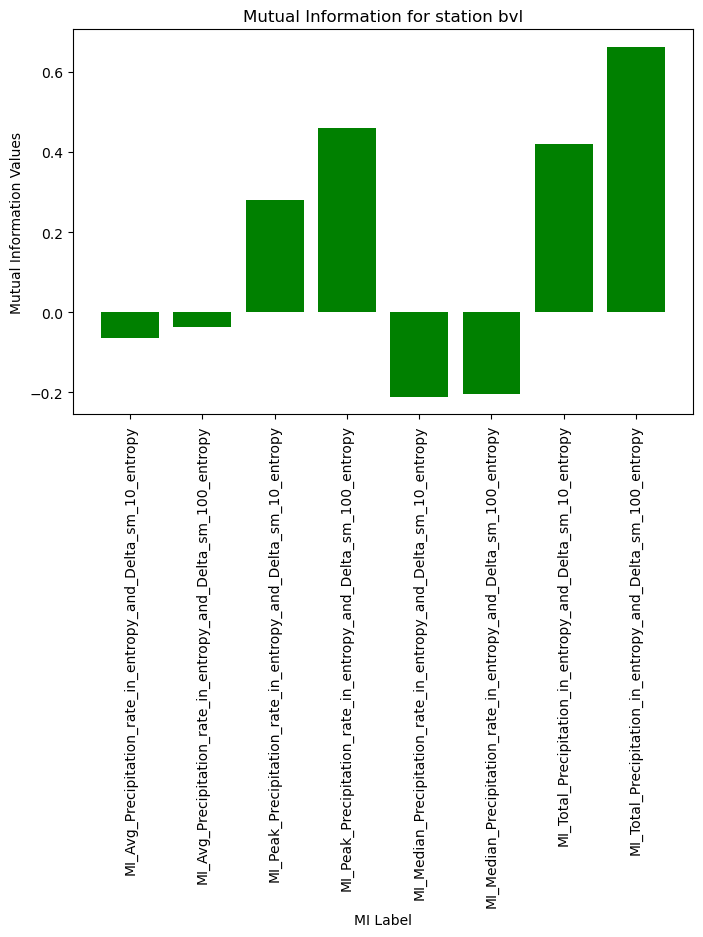

/tmp/ipykernel_64769/2360902302.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


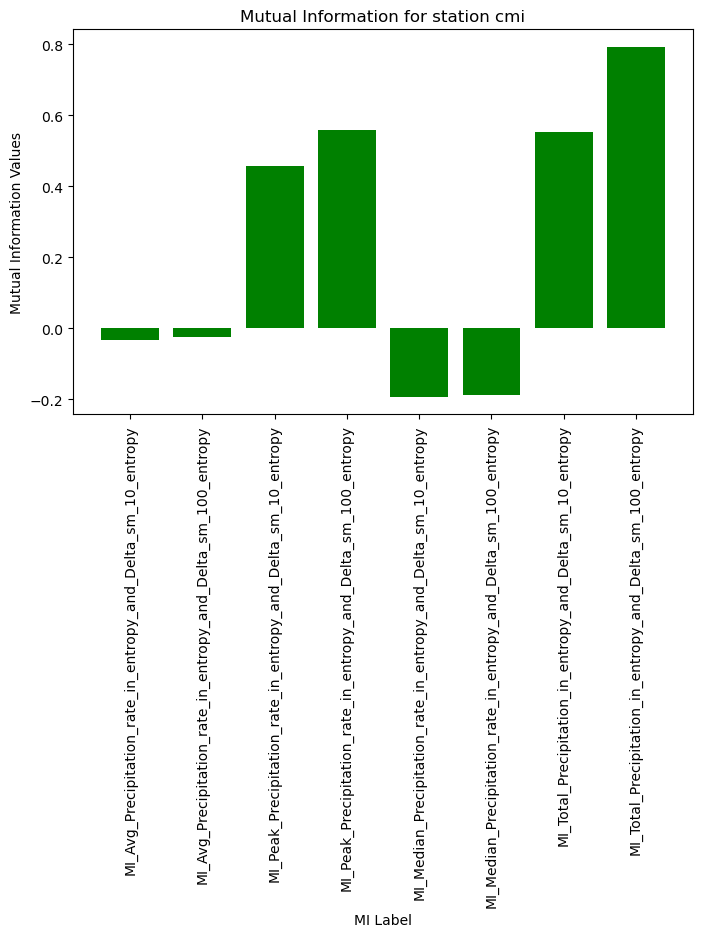

/tmp/ipykernel_64769/2360902302.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


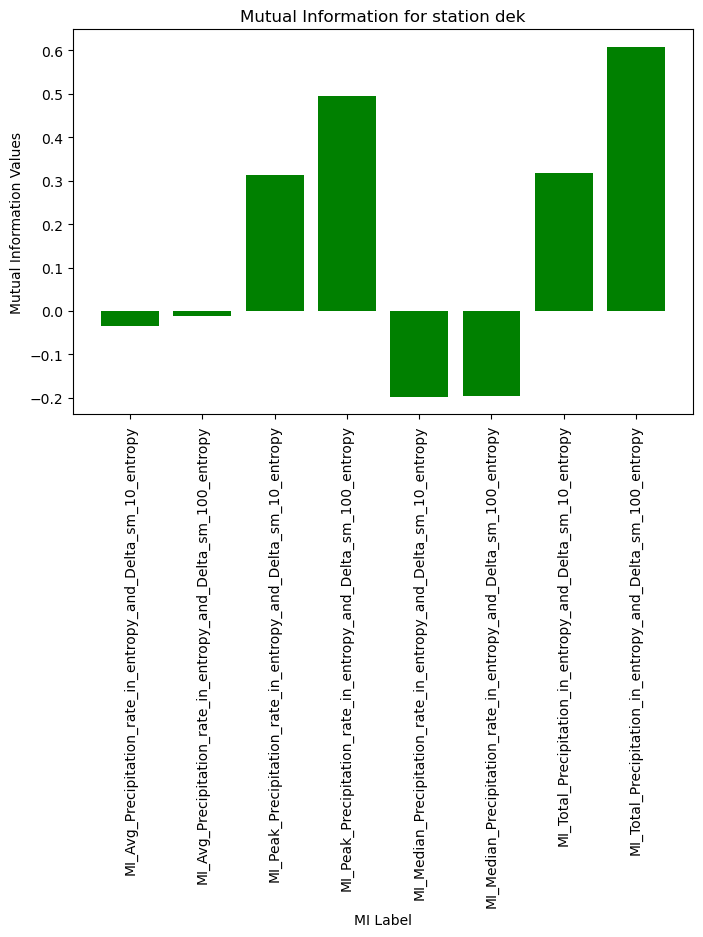

/tmp/ipykernel_64769/2360902302.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


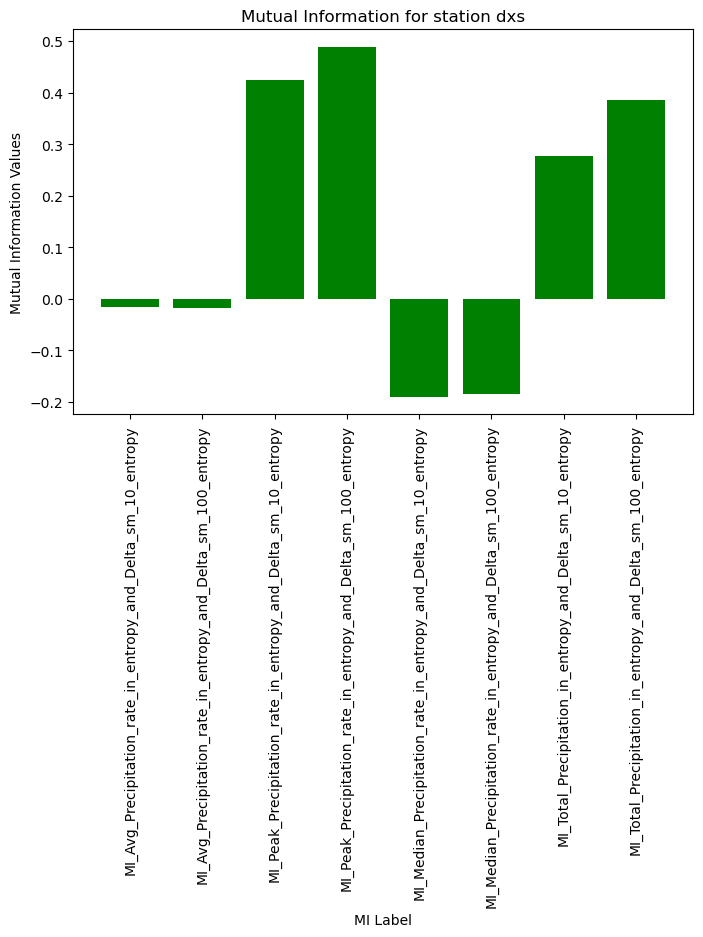

/tmp/ipykernel_64769/2360902302.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


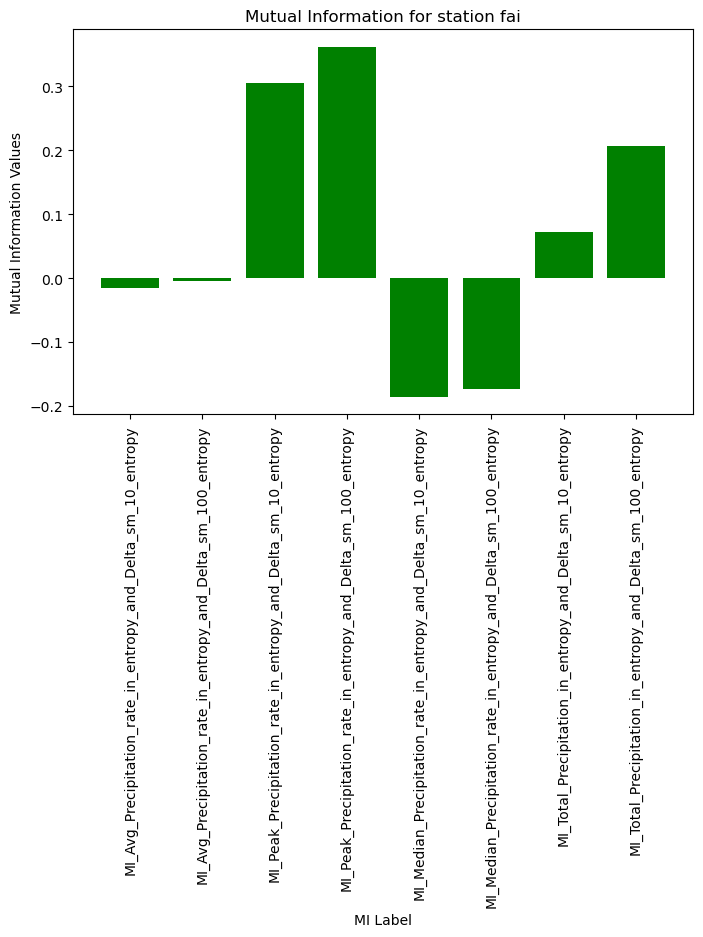

/tmp/ipykernel_64769/2360902302.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


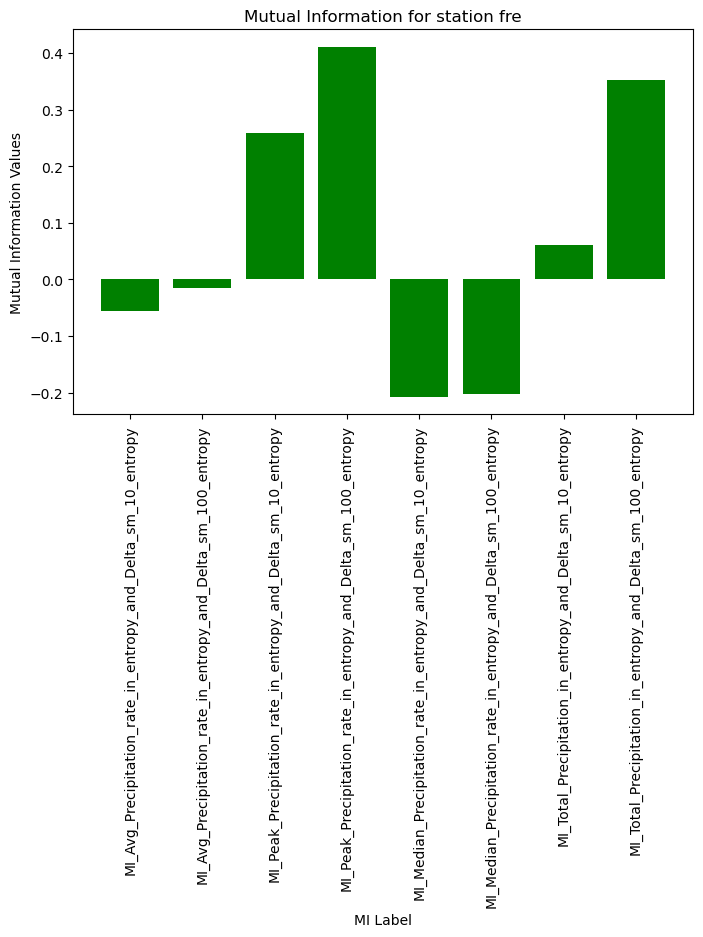

/tmp/ipykernel_64769/2360902302.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


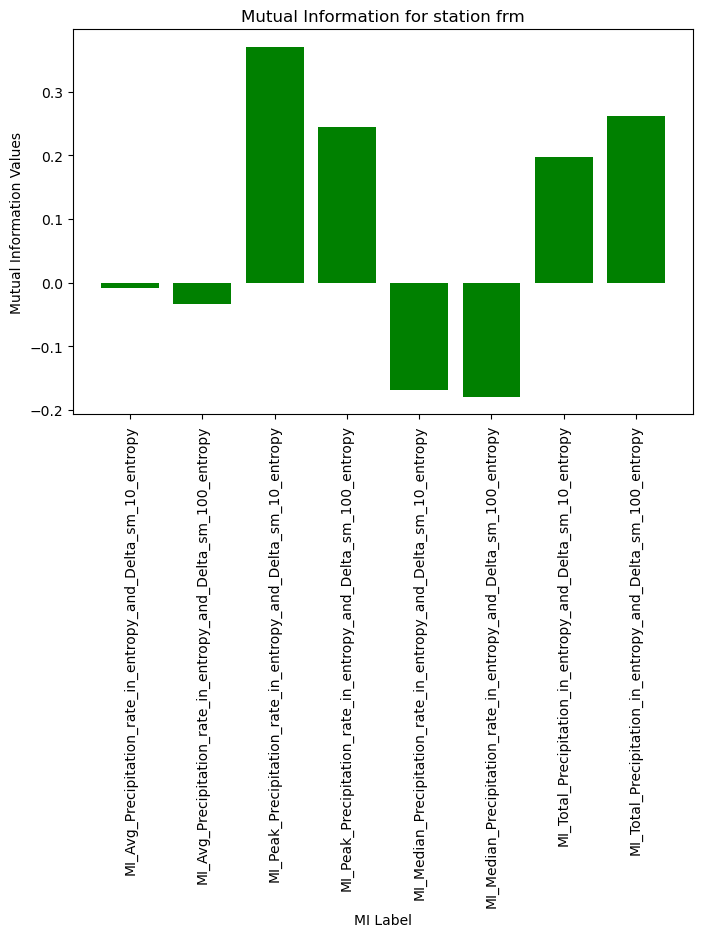

/tmp/ipykernel_64769/2360902302.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


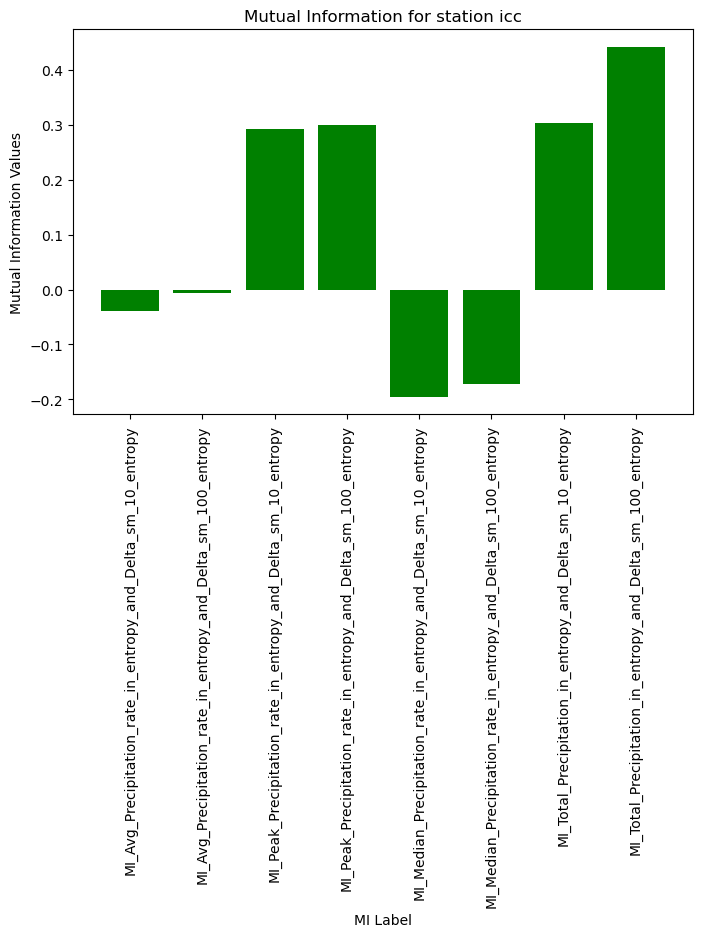

/tmp/ipykernel_64769/2360902302.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


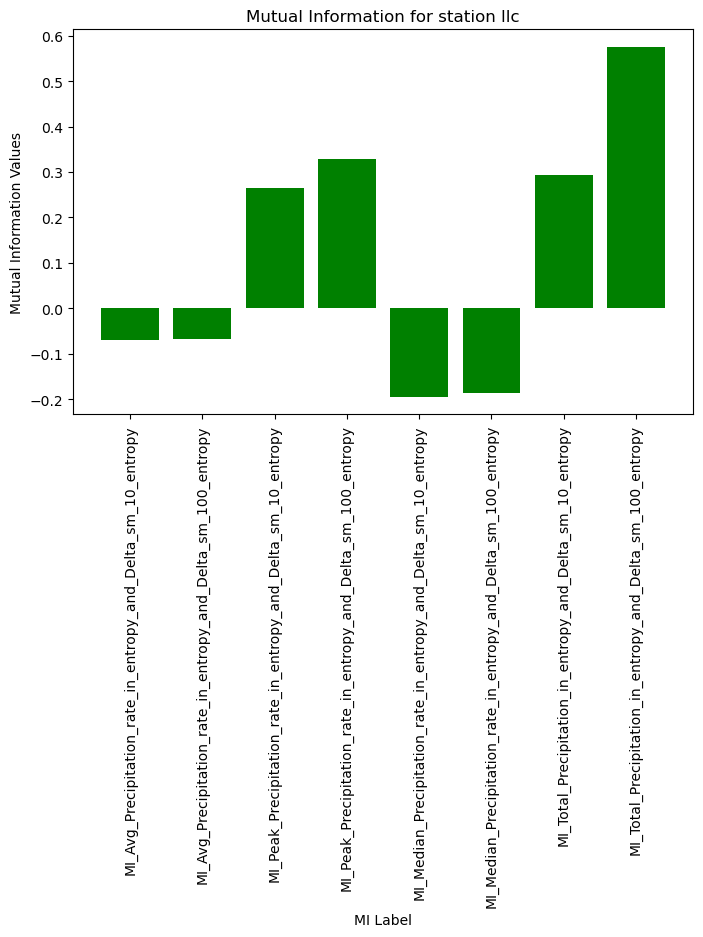

/tmp/ipykernel_64769/2360902302.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


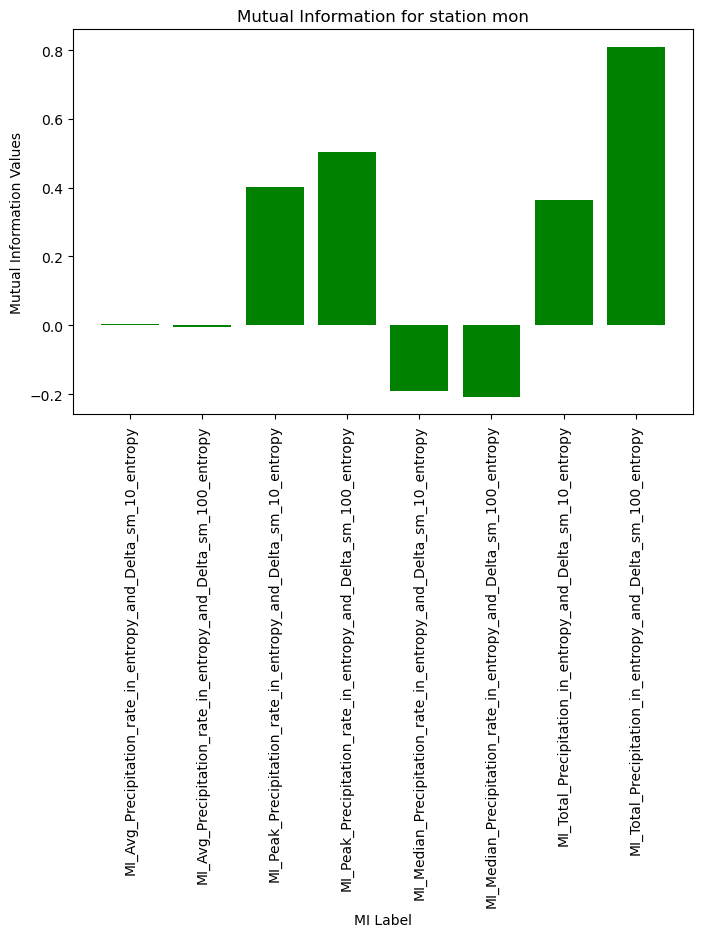

/tmp/ipykernel_64769/2360902302.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


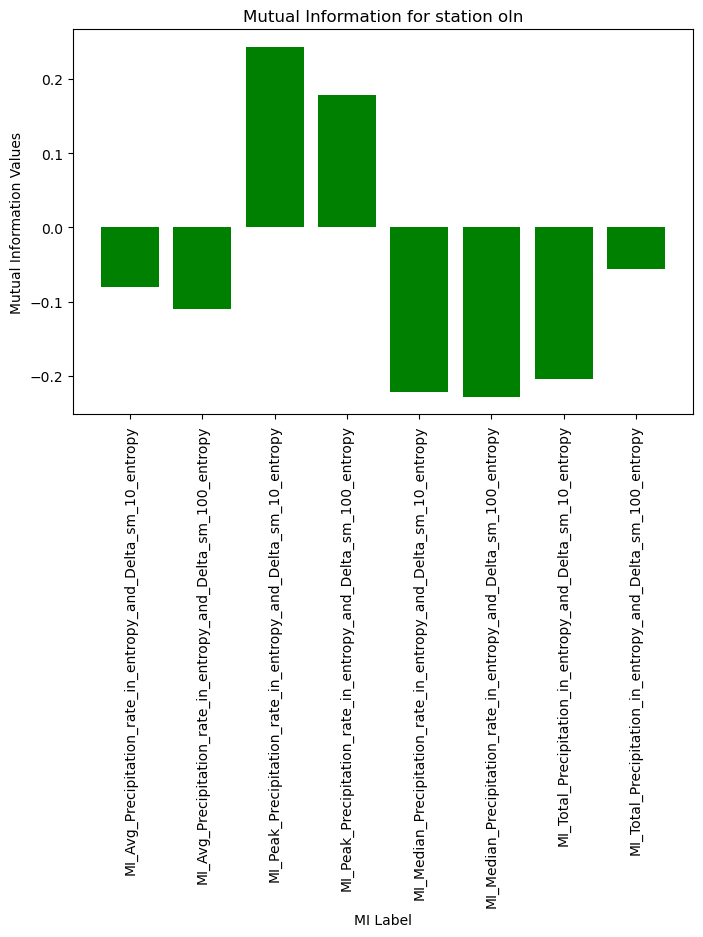

/tmp/ipykernel_64769/2360902302.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


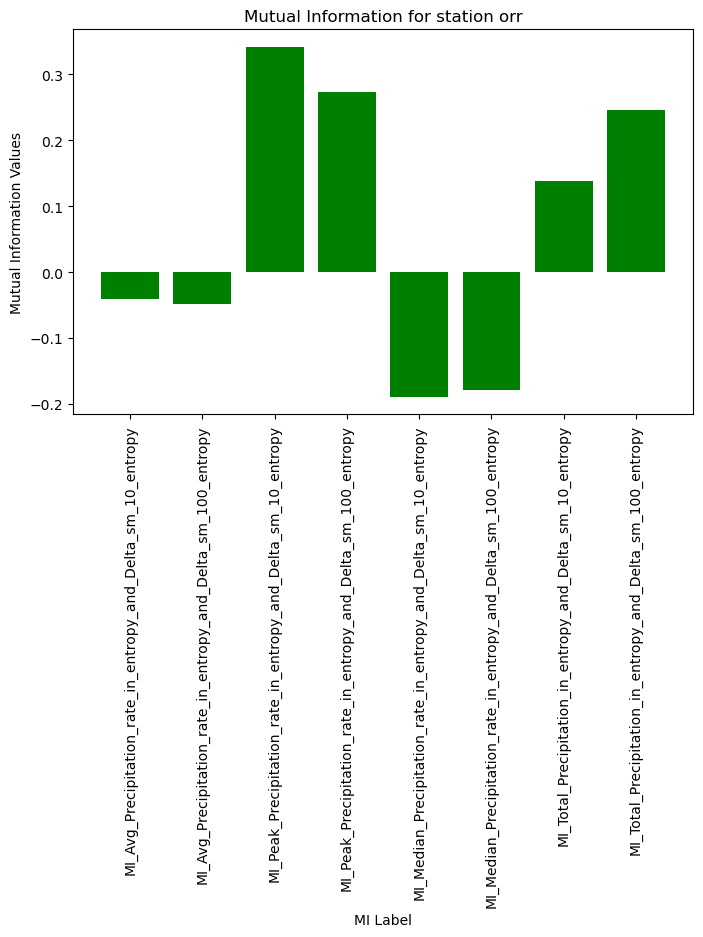

/tmp/ipykernel_64769/2360902302.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


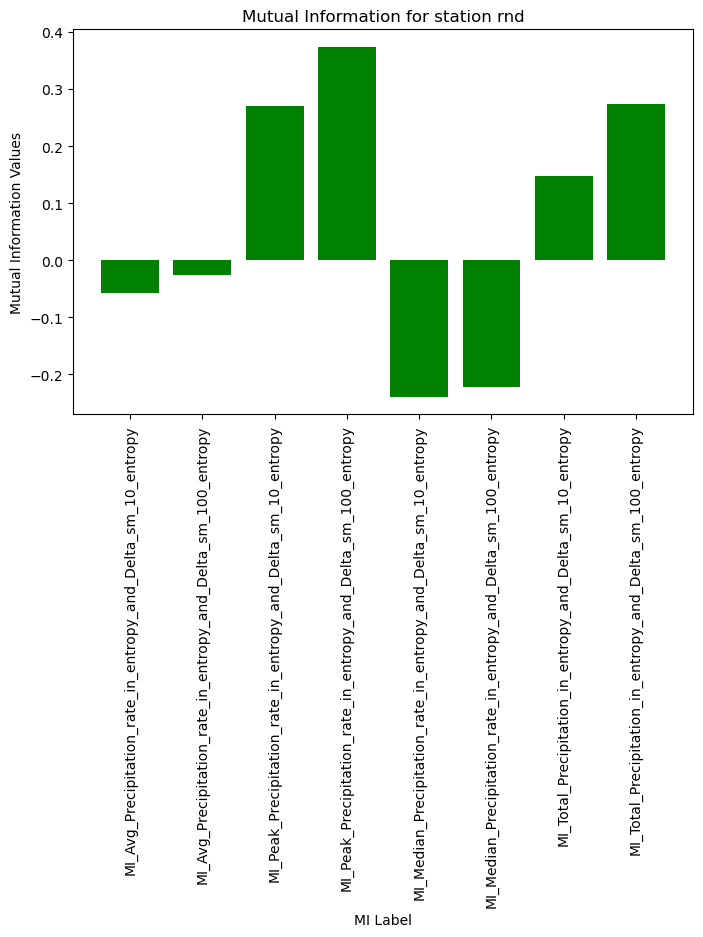

/tmp/ipykernel_64769/2360902302.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


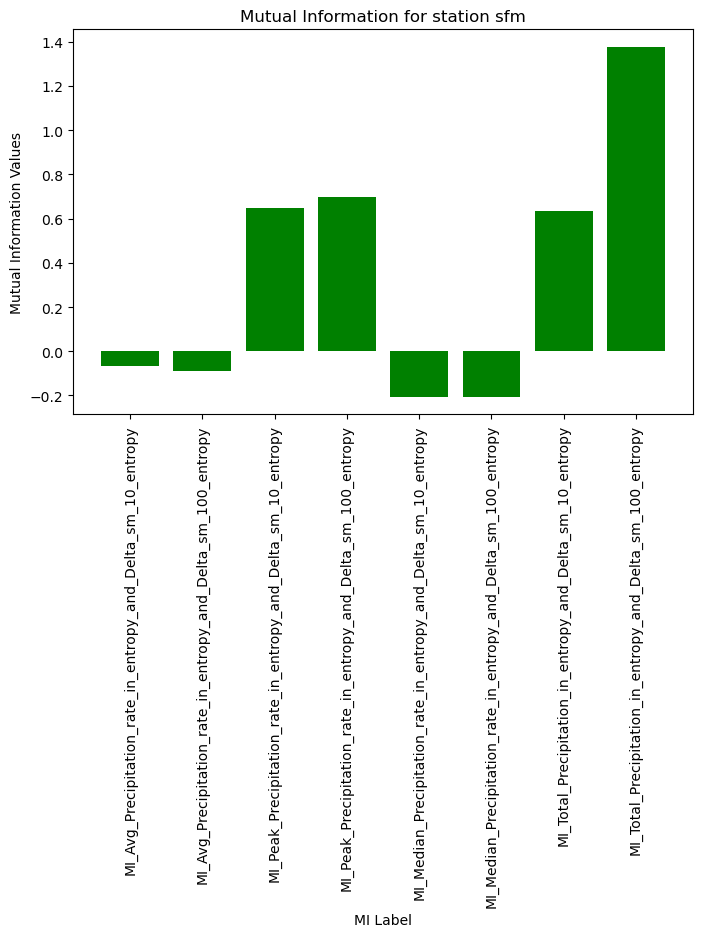

/tmp/ipykernel_64769/2360902302.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


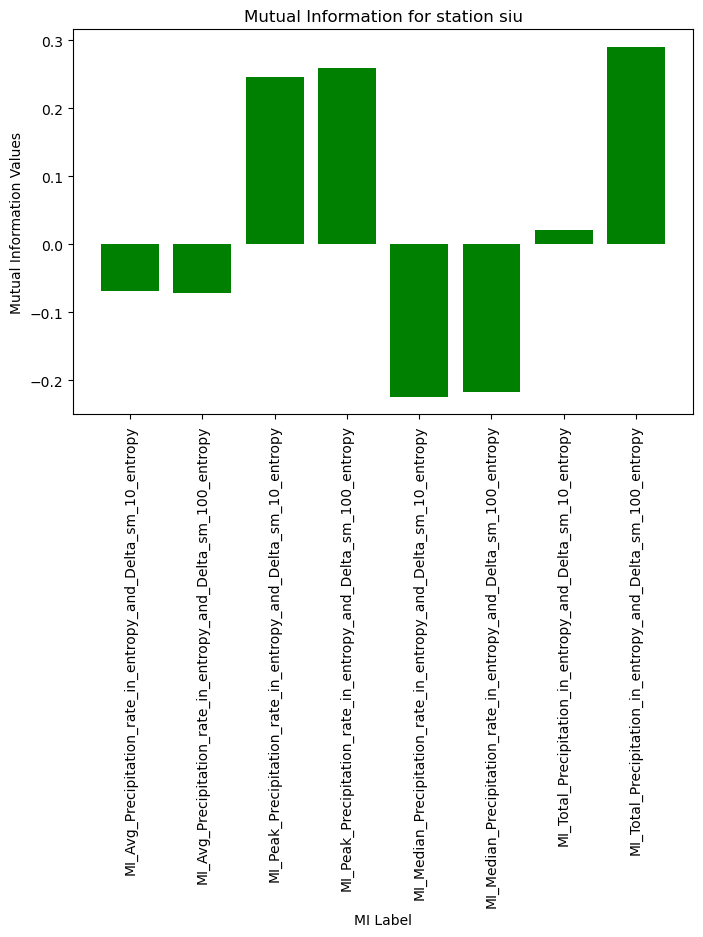

/tmp/ipykernel_64769/2360902302.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


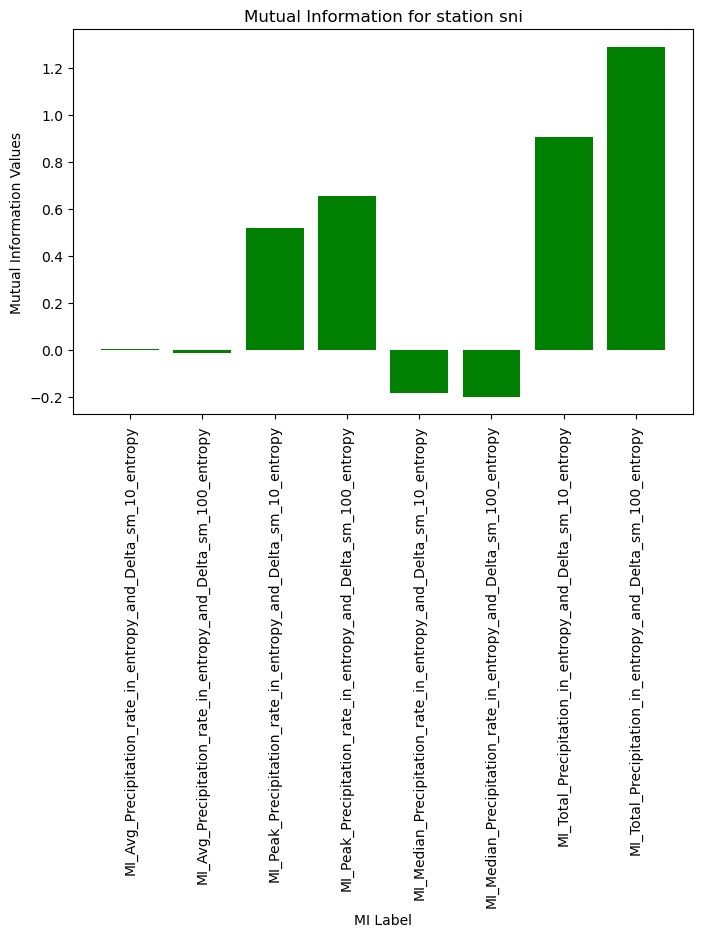

/tmp/ipykernel_64769/2360902302.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


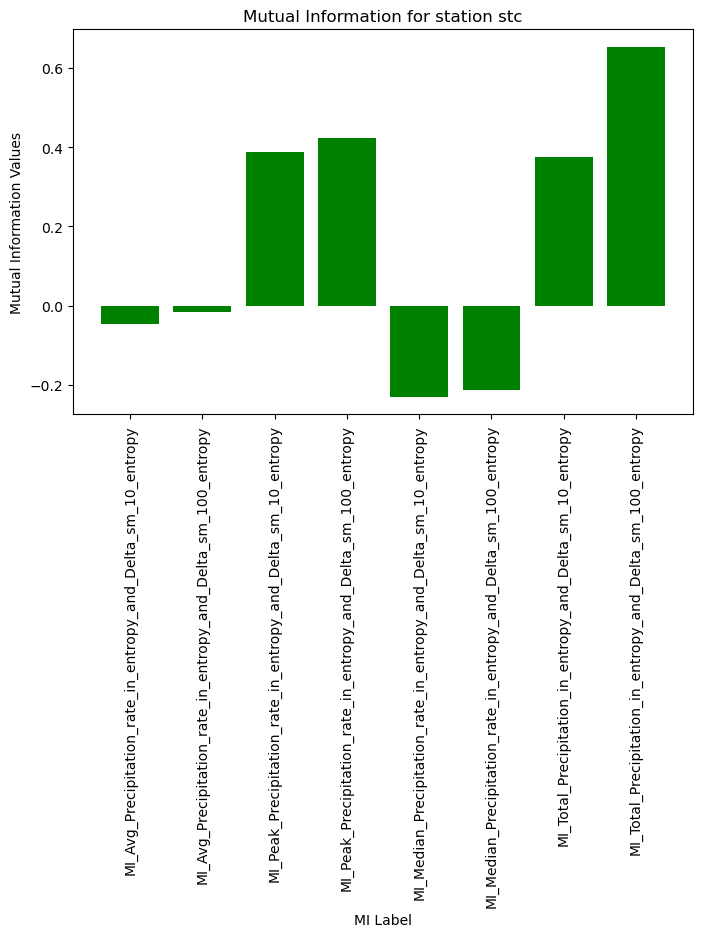

/tmp/ipykernel_64769/2360902302.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


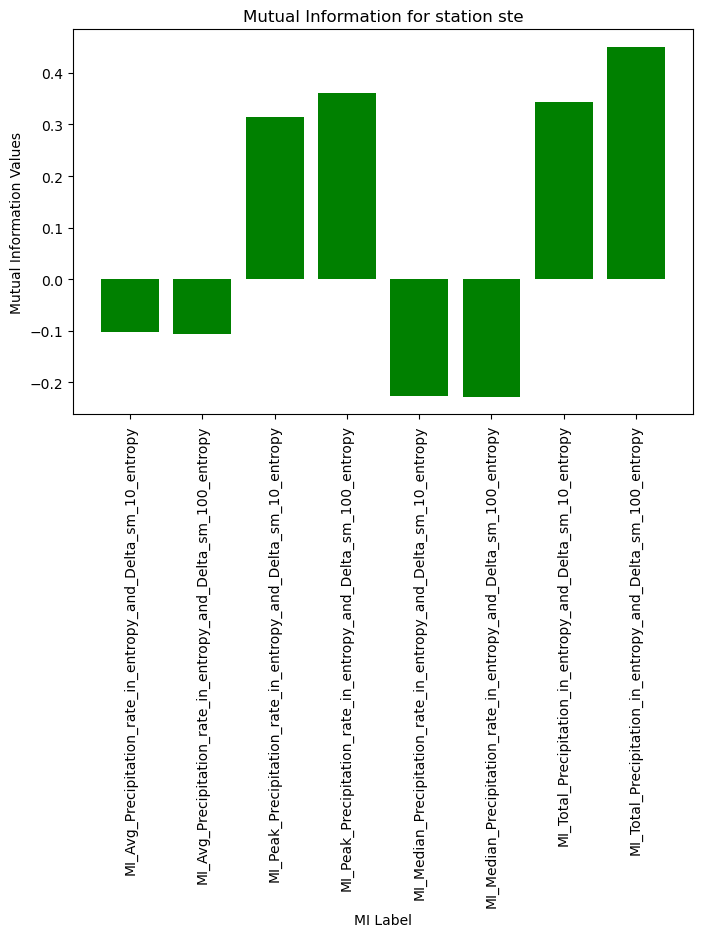

In [171]:
stations = MIs.station.unique()

for s in stations:
    station_MI = MIs.loc[MIs['station'] == s]
    fig, ax = plt.subplots(figsize = (8,5))
    ax.bar(station_MI.MI_label, station_MI.mutual_information, color = 'green')
    ax.set_title(f"Mutual Information for station {s}")
    ax.set_xlabel("MI Label")
    ax.set_ylabel("Mutual Information Values")
    ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability
    plt.show()
    
    
